#Import Python Libraries

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

#Data Load
Data is loaded in Python.

In [33]:
url = "https://raw.githubusercontent.com/Sponono/Sponono-DASC8412w/main/School_Data_CSV.csv"
df = pd.read_csv(url, encoding='latin-1', low_memory=False)

df.head()

,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


In [34]:
df.shape

(199853, 9)

There are 199853 rows (observations) and 9 columns

#Data Cleaning
Null values and duplicates are checked to ensure data completeness and prevent biased or misleading results, and data types are verified to confirm that each variable is correctly classified for accurate analysis.

In [35]:
df.duplicated().sum()

np.int64(799)

The above results confirm that there are 799 duplicat records in the dataset. The duplicates will be removed.

In [36]:
df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

Duplicates have been removed.

In [37]:
df.isnull().sum()

,0
emisno,0
centername,5931
institution_name,65448
centreno,16
quintile,2799
ward_id,767
street_address,6684
new_long,32092
new_lat,115418


The dataset has complete EMIS numbers, which makes it easy to identify schools. However, several other fields have many missing values. More than 65,000 records do not have school names, making it harder to identify schools, prepare reports, and find duplicates. The location data also has major problems, with 32,092 missing longitudes and 115,418 missing latitudes. This makes it difficult to map schools and analyse overcrowding by location, some records are also missing quintile and ward_id information, which may affect comparisons between schools in different socio-economic groups and municipal areas. Missing street addresses also make it harder to confirm school locations. The dataset is suitable for analysing overcrowding at provincial level and by quintile. However, it is not suitable for geographic analysis until the missing location data is corrected or added.

##Matplotlib Model

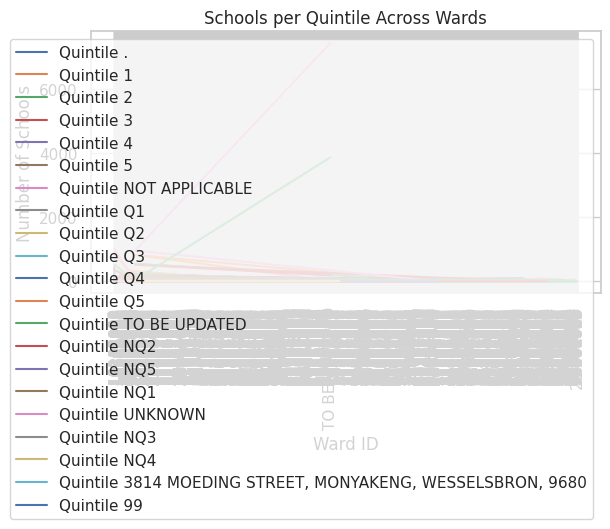

In [40]:

plot_data = df.copy()
counts = df.groupby(['ward_id', 'quintile']).size().reset_index(name='school_count')

for q in counts['quintile'].unique():
    subset = counts[counts['quintile'] == q]
    plt.plot(subset['ward_id'], subset['school_count'], label=f'Quintile {q}')

plt.xlabel("Ward ID")
plt.ylabel("Number of Schools")
plt.title("Schools per Quintile Across Wards")
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

The line plot shows that the quintile data in the dataset is badly corrupted, with more than 20 different categories. These include valid quintiles, missing values, text labels, incorrect codes, and even full addresses. This makes the graph confusing and difficult to interpret. Although the plot shows differences in school counts across wards, the quintile data must first be cleaned and standardized to values from 1 to 5 before accurate socio-economic or overcrowding analysis can be done.

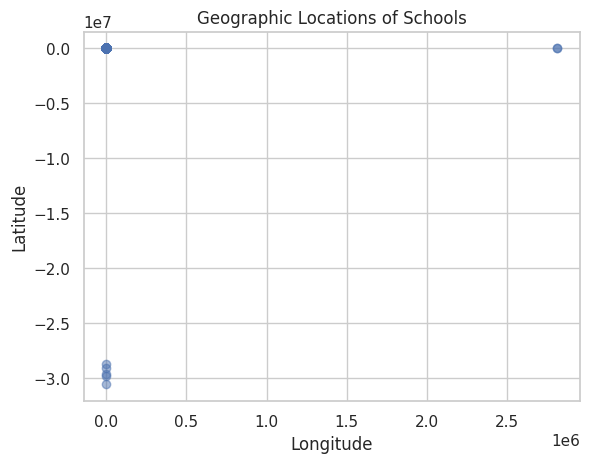

In [43]:
# Clean and convert coordinate columns to numeric values
scatter_data = df.copy()
scatter_data['new_long'] = pd.to_numeric(scatter_data['new_long'], errors='coerce')
scatter_data['new_lat'] = pd.to_numeric(scatter_data['new_lat'], errors='coerce')

# Drop rows where coordinates are missing
scatter_data = scatter_data.dropna(subset=['new_long', 'new_lat'])

plt.scatter(scatter_data['new_long'], scatter_data['new_lat'], alpha=0.5)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Locations of Schools")
plt.show()

The scatter plot shows that the latitude and longitude data in the dataset are incorrect. The points have extremely large values that fall outside South Africa’s geographic boundaries. Most points are clustered in one corner, while a few are far away, making the plot difficult to interpret. South African latitude values should be roughly between -35 and -22, and longitude values between 16 and 33. The values in the new_lat and new_long fields are therefore likely corrupted or incorrectly formatted. These fields must be cleaned or replaced before the data can be used for mapping or spatial analysis.

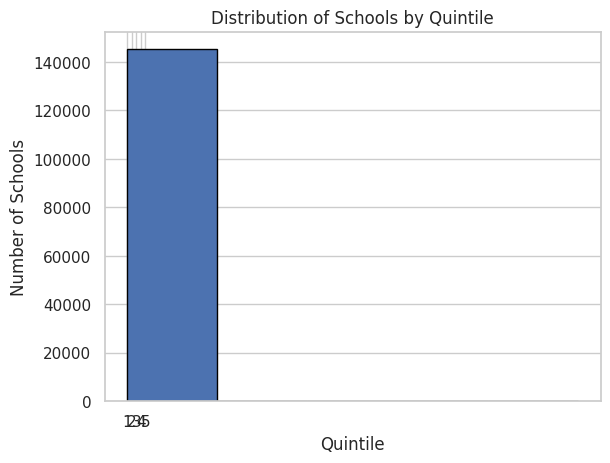

In [44]:
# Clean the quintile column: convert to numeric, converting invalid values and strings to NaN
clean_quintile = pd.to_numeric(df['quintile'], errors='coerce')

# Drop NaN values
clean_quintile = clean_quintile.dropna()

# Plot the histogram with the cleaned numeric data
plt.hist(clean_quintile, bins=5, edgecolor='black')
plt.xlabel("Quintile")
plt.ylabel("Number of Schools")
plt.title("Distribution of Schools by Quintile")
plt.xticks([1, 2, 3, 4, 5])
plt.show()

The histogram shows that almost all schools fall into one quintile category, with around 145,000 schools in that group and very few in the others. This suggests that the quintile data may be incorrect or not properly cleaned. In South Africa, school quintiles range from 1 to 5 and represent different socio-economic categories. The data must be cleaned, standardised, and checked before it can be used for accurate socio-economic or overcrowding analysis.

##Matplotlib and Seaborn Model

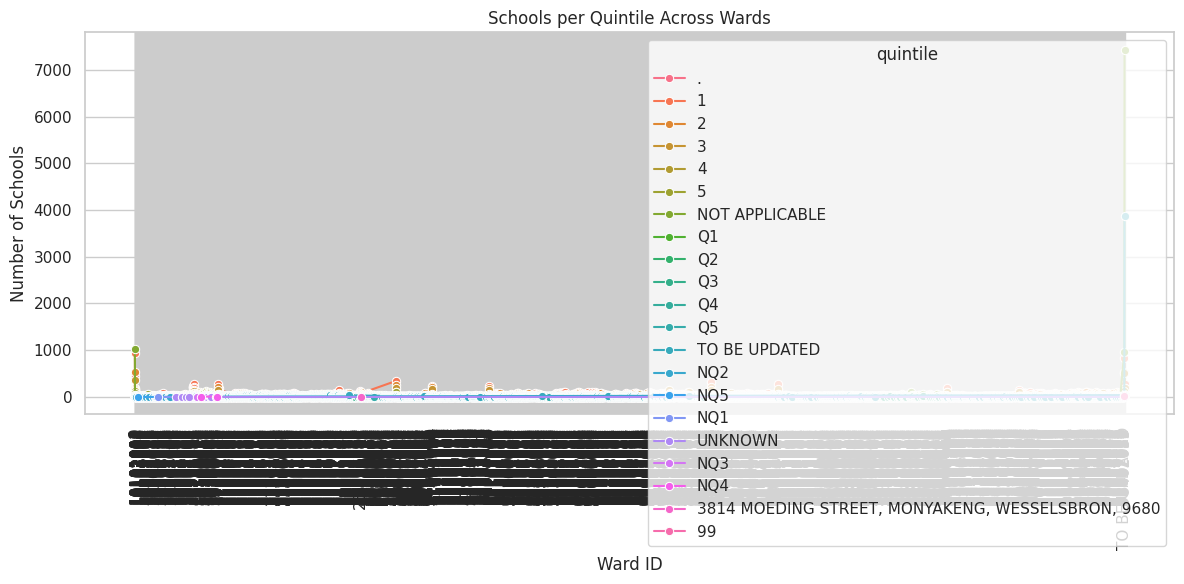

In [45]:
plt.figure(figsize=(12,6))
sns.lineplot(data=counts, x='ward_id', y='school_count', hue='quintile', marker='o')
plt.title("Schools per Quintile Across Wards")
plt.xlabel("Ward ID")
plt.ylabel("Number of Schools")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

The scatter plot shows the number of schools in each ward according to quintile, but the quintile data is incorrect. Instead of the expected five categories (1–5), there are more than 20 different labels, including text, missing values, “UNKNOWN,” “NOT APPLICABLE,” and even a street address. This makes the graph cluttered and difficult to understand. Although some wards have more schools than others, the quintile data must be cleaned and standardised before accurate analysis of school distribution, socio-economic differences, and equity can be done.

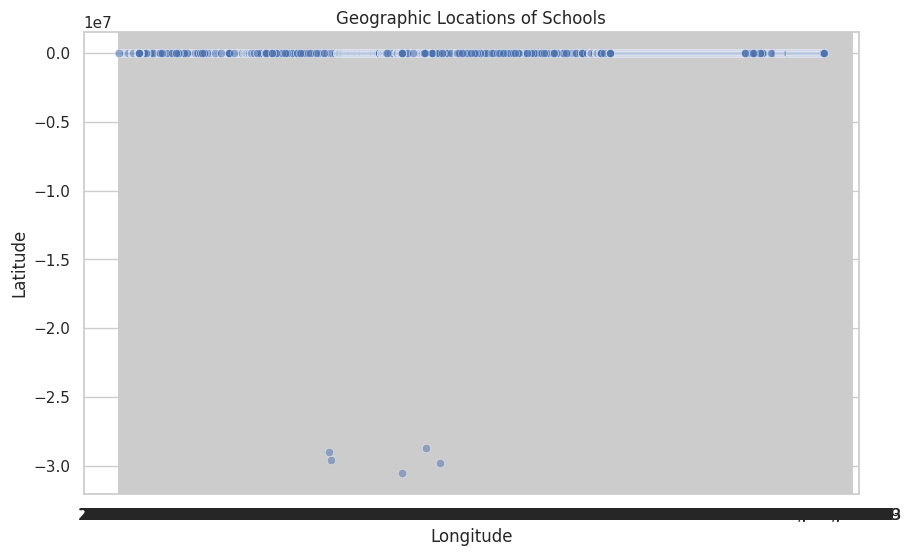

In [46]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='new_long', y='new_lat', alpha=0.5)
plt.title("Geographic Locations of Schools")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

The geographic scatter plot shows that the latitude and longitude values in the dataset are incorrect. The values fall outside South Africa’s normal geographic ranges, with some latitudes close to zero and others near -30 million. This suggests that the new_lat and new_long fields may contain errors, such as missing decimal points or incorrect formatting. The coordinate data must be corrected or replaced before it can be used to map school locations or analyse geographic patterns and overcrowding.

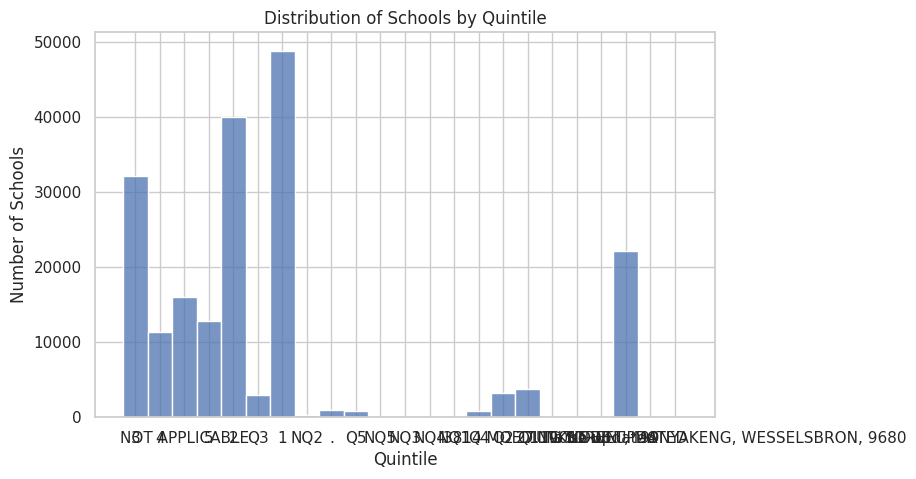

In [47]:
plt.figure(figsize=(8,5))
sns.histplot(df['quintile'], bins=5, kde=False)
plt.title("Distribution of Schools by Quintile")
plt.xlabel("Quintile")
plt.ylabel("Number of Schools")
plt.show()

The histogram shows an uneven distribution of schools across quintile categories, with some categories containing thousands of schools while others have very few. The labels overlap, and the data includes incorrect or inconsistent entries, such as “NQ2,” “EQ3,” and non-numeric values. This indicates that the quintile field has not been properly cleaned. The data must be corrected and standardised to the five categories (1–5) before meaningful conclusions can be drawn about the socio-economic distribution and equity of schools.

The histogram shows an uneven distribution of schools across quintile categories, with some categories containing thousands of schools while others have very few. The labels overlap, and the data includes incorrect or inconsistent entries, such as “NQ2,” “EQ3,” and non-numeric values. This indicates that the quintile field has not been properly cleaned. The data must be corrected and standardized to the five categories (1–5) before meaningful conclusions can be drawn about the socio-economic distribution and equity of schools.
Model 1 is simple and easy to understand. It uses basic Matplotlib functions and fewer libraries, making it suitable for beginners and basic data analysis. However, the graphs become difficult to interpret because the dataset contains incorrect quintile categories and invalid coordinates. Its basic styling also makes it harder to identify patterns and data errors.
Model 2 uses Seaborn to create more attractive and clearer graphs through better colours, styling, and features such as KDE curves. It makes data problems easier to identify, such as incorrect quintile categories and invalid latitude and longitude values. This makes it more useful for exploring and understanding the problems in the dataset.
Model 1 is best for beginners and simple analysis, while Model 2 is more suitable for academic research and professional reports because it produces clearer visualisations. Overall, Model 1 is better for simplicity, while Model 2 is better for detailed analysis and identifying data quality issues. However, both models require clean and accurate data to produce reliable results.
